In [2]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

DATA_PATH = "deidentified_overlap_tcia.csv.cleaned.csv_20210806.csv"

df = pd.read_csv(DATA_PATH, low_memory=False)

print("Dataset shape:", df.shape)
print("Unique patients:", df["to_patient_id"].nunique())
print(df.head())

Dataset shape: (1384, 131)
Unique patients: 1384
  to_patient_id covid19_statuses last.status age.splits gender_concept_name  \
0       A917122         positive  discharged    (74,90]              FEMALE   
1       A387558         positive    deceased    (74,90]                MALE   
2       A968238         positive    deceased    (74,90]                MALE   
3       A106133         positive    deceased    (74,90]              FEMALE   
4       A300871         positive    deceased    (74,90]              FEMALE   

  visit_start_datetime visit_concept_name  is_icu was_ventilated  \
0             1/1/1901    Inpatient Visit   False             No   
1             1/1/1901    Inpatient Visit    True             No   
2             1/5/1901    Inpatient Visit    True            Yes   
3             1/1/1901    Inpatient Visit   False             No   
4             1/1/1901    Inpatient Visit   False             No   

   invasive_vent_days  ...  \
0                 NaN  ...   
1      

In [3]:
def convert_binary(series):
    return series.astype("string").str.strip().str.lower().map({
        "true": 1,
        "yes": 1,
        "1": 1,
        "y": 1,
        "false": 0,
        "no": 0,
        "0": 0,
        "n": 0
    })

targets = pd.DataFrame(index=df.index)

targets["ICU"] = convert_binary(df["is_icu"])

targets["Ventilation"] = convert_binary(
    df["was_ventilated"]
)

status = df["last.status"].astype("string").str.strip().str.lower()

# Exclude unknown statuses for the death target.
targets["Death"] = status.map({
    "deceased": 1,
    "discharged": 0
})

for col in targets.columns:
    print("\n", col)
    print(targets[col].value_counts(dropna=False))


 ICU
ICU
0    1124
1     260
Name: count, dtype: int64

 Ventilation
Ventilation
0    1171
1     213
Name: count, dtype: int64

 Death
Death
0    1201
1     183
Name: count, dtype: int64


In [4]:
candidate_features = [
    "age.splits",
    "gender_concept_name",
    "days_prior_sx",
    "smoking_status_v",

    "cough_v",
    "dyspnea_admission_v",
    "nausea_v",
    "vomiting_v",
    "diarrhea_v",
    "abdominal_pain_v",
    "fever_v",

    "htn_v",
    "dm_v",
    "cad_v",
    "hf_ef_v",
    "ckd_v",
    "malignancies_v",
    "copd_v",
    "other_lung_disease_v",

    "BMI.over30",
    "BMI.over35",
    "temperature.over38",
    "pulseOx.under90",
    "Respiration.over24",
    "HeartRate.over100",

    "8331-1_Oral temperature",
    "59408-5_Oxygen saturation in Arterial blood by Pulse oximetry",
    "9279-1_Respiratory rate",
    "76282-3_Heart rate.beat-to-beat by EKG",
    "8480-6_Systolic blood pressure",

    "33256-9_Leukocytes [#/volume] corrected for nucleated erythrocytes in Blood by Automated count",
    "751-8_Neutrophils [#/volume] in Blood by Automated count",
    "731-0_Lymphocytes [#/volume] in Blood by Automated count",
    "2951-2_Sodium [Moles/volume] in Serum or Plasma",
    "1920-8_Aspartate aminotransferase [Enzymatic activity/volume] in Serum or Plasma",
    "2160-0_Creatinine [Mass/volume] in Serum or Plasma",
    "39156-5_Body mass index (BMI) [Ratio]"
]

feature_cols = [
    c for c in candidate_features
    if c in df.columns
]

print("Features available:", len(feature_cols))
print(feature_cols)

if not feature_cols:
    raise ValueError("No candidate features found. Check the CSV columns.")

X = df[feature_cols].copy()

Features available: 37
['age.splits', 'gender_concept_name', 'days_prior_sx', 'smoking_status_v', 'cough_v', 'dyspnea_admission_v', 'nausea_v', 'vomiting_v', 'diarrhea_v', 'abdominal_pain_v', 'fever_v', 'htn_v', 'dm_v', 'cad_v', 'hf_ef_v', 'ckd_v', 'malignancies_v', 'copd_v', 'other_lung_disease_v', 'BMI.over30', 'BMI.over35', 'temperature.over38', 'pulseOx.under90', 'Respiration.over24', 'HeartRate.over100', '8331-1_Oral temperature', '59408-5_Oxygen saturation in Arterial blood by Pulse oximetry', '9279-1_Respiratory rate', '76282-3_Heart rate.beat-to-beat by EKG', '8480-6_Systolic blood pressure', '33256-9_Leukocytes [#/volume] corrected for nucleated erythrocytes in Blood by Automated count', '751-8_Neutrophils [#/volume] in Blood by Automated count', '731-0_Lymphocytes [#/volume] in Blood by Automated count', '2951-2_Sodium [Moles/volume] in Serum or Plasma', '1920-8_Aspartate aminotransferase [Enzymatic activity/volume] in Serum or Plasma', '2160-0_Creatinine [Mass/volume] in Ser

In [5]:
for col in X.columns:
    converted = pd.to_numeric(X[col], errors="coerce")

    original_count = X[col].notna().sum()

    if (
        original_count > 0
        and converted.notna().sum() / original_count >= 0.85
    ):
        X[col] = converted

numeric_cols = X.select_dtypes(
    include=["number", "bool"]
).columns.tolist()

categorical_cols = [
    c for c in X.columns
    if c not in numeric_cols
]

preprocessor = ColumnTransformer([
    (
        "numeric",
        Pipeline([
            ("imputer", SimpleImputer(strategy="median"))
        ]),
        numeric_cols
    ),
    (
        "categorical",
        Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore"))
        ]),
        categorical_cols
    )
])

print("Numeric features:", len(numeric_cols))
print("Categorical features:", len(categorical_cols))

Numeric features: 19
Categorical features: 18


In [6]:
work = df[["to_patient_id"] + feature_cols].copy()
work = work.join(targets)


def first_nonmissing(series):
    series = series.dropna()
    return series.iloc[0] if len(series) else np.nan


def aggregate_patient(group):
    row = {
        col: first_nonmissing(group[col])
        for col in feature_cols
    }

    for target in ["ICU", "Ventilation", "Death"]:
        values = group[target].dropna()
        row[target] = (
            int(values.max())
            if len(values)
            else np.nan
        )

    return pd.Series(row)


patient_df = (
    work.dropna(subset=["to_patient_id"])
    .groupby("to_patient_id", sort=False)
    .apply(aggregate_patient)
    .reset_index()
)

print("Patient-level rows:", len(patient_df))


# Recreate features from patient-level data.
X_all = patient_df[feature_cols].copy()

for col in X_all.columns:
    converted = pd.to_numeric(
        X_all[col],
        errors="coerce"
    )

    count = X_all[col].notna().sum()

    if count and converted.notna().sum() / count >= 0.85:
        X_all[col] = converted


numeric_cols = X_all.select_dtypes(
    include=["number", "bool"]
).columns.tolist()

categorical_cols = [
    c for c in X_all.columns
    if c not in numeric_cols
]

preprocessor = ColumnTransformer([
    (
        "numeric",
        Pipeline([
            ("imputer", SimpleImputer(strategy="median"))
        ]),
        numeric_cols
    ),
    (
        "categorical",
        Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore"))
        ]),
        categorical_cols
    )
])


results = []
trained_models = {}

for target in ["ICU", "Ventilation", "Death"]:

    print("\n" + "=" * 60)
    print("TARGET:", target)

    valid = patient_df[target].notna()

    X_target = X_all.loc[valid]
    y_target = patient_df.loc[valid, target].astype(int)

    print("Usable patients:", len(y_target))
    print("Class counts:", y_target.value_counts().to_dict())

    if (
        y_target.nunique() < 2
        or y_target.value_counts().min() < 2
    ):
        print("Skipping: insufficient examples of both classes.")
        continue

    X_train, X_test, y_train, y_test = train_test_split(
        X_target,
        y_target,
        test_size=0.20,
        random_state=42,
        stratify=y_target
    )

    model = Pipeline([
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                max_iter=2000,
                class_weight="balanced",
                solver="liblinear",
                random_state=42
            )
        )
    ])

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    metrics = {
        "Target": target,
        "N": len(y_target),
        "Test N": len(y_test),
        "Positive rate": y_target.mean(),
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_test, predictions, zero_division=0
        ),
        "ROC-AUC": (
            roc_auc_score(y_test, probabilities)
            if y_test.nunique() == 2
            else np.nan
        )
    }

    results.append(metrics)
    trained_models[target] = model

    print(pd.Series(metrics).to_string())

    print("\nConfusion matrix:")
    print(confusion_matrix(
        y_test,
        predictions,
        labels=[0, 1]
    ))

    print("\nClassification report:")
    print(classification_report(
        y_test,
        predictions,
        labels=[0, 1],
        zero_division=0
    ))


results_df = pd.DataFrame(results)

print("\nFINAL MODEL COMPARISON")
display(results_df.round(3))

Patient-level rows: 1384

TARGET: ICU
Usable patients: 1384
Class counts: {0: 1124, 1: 260}
Target                ICU
N                    1384
Test N                277
Positive rate    0.187861
Accuracy         0.736462
Precision         0.37037
Recall           0.576923
F1               0.451128
ROC-AUC          0.757607

Confusion matrix:
[[174  51]
 [ 22  30]]

Classification report:
              precision    recall  f1-score   support

           0       0.89      0.77      0.83       225
           1       0.37      0.58      0.45        52

    accuracy                           0.74       277
   macro avg       0.63      0.68      0.64       277
weighted avg       0.79      0.74      0.76       277


TARGET: Ventilation
Usable patients: 1384
Class counts: {0: 1171, 1: 213}
Target           Ventilation
N                       1384
Test N                   277
Positive rate       0.153902
Accuracy            0.700361
Precision           0.287234
Recall              0.627907
F1 

,Target,N,Test N,Positive rate,Accuracy,Precision,Recall,F1,ROC-AUC
0,ICU,1384,277,0.188,0.736,0.370,0.577,0.451,0.758
1,Ventilation,1384,277,0.154,0.700,0.287,0.628,0.394,0.745
2,Death,1384,277,0.132,0.816,0.403,0.784,0.532,0.852


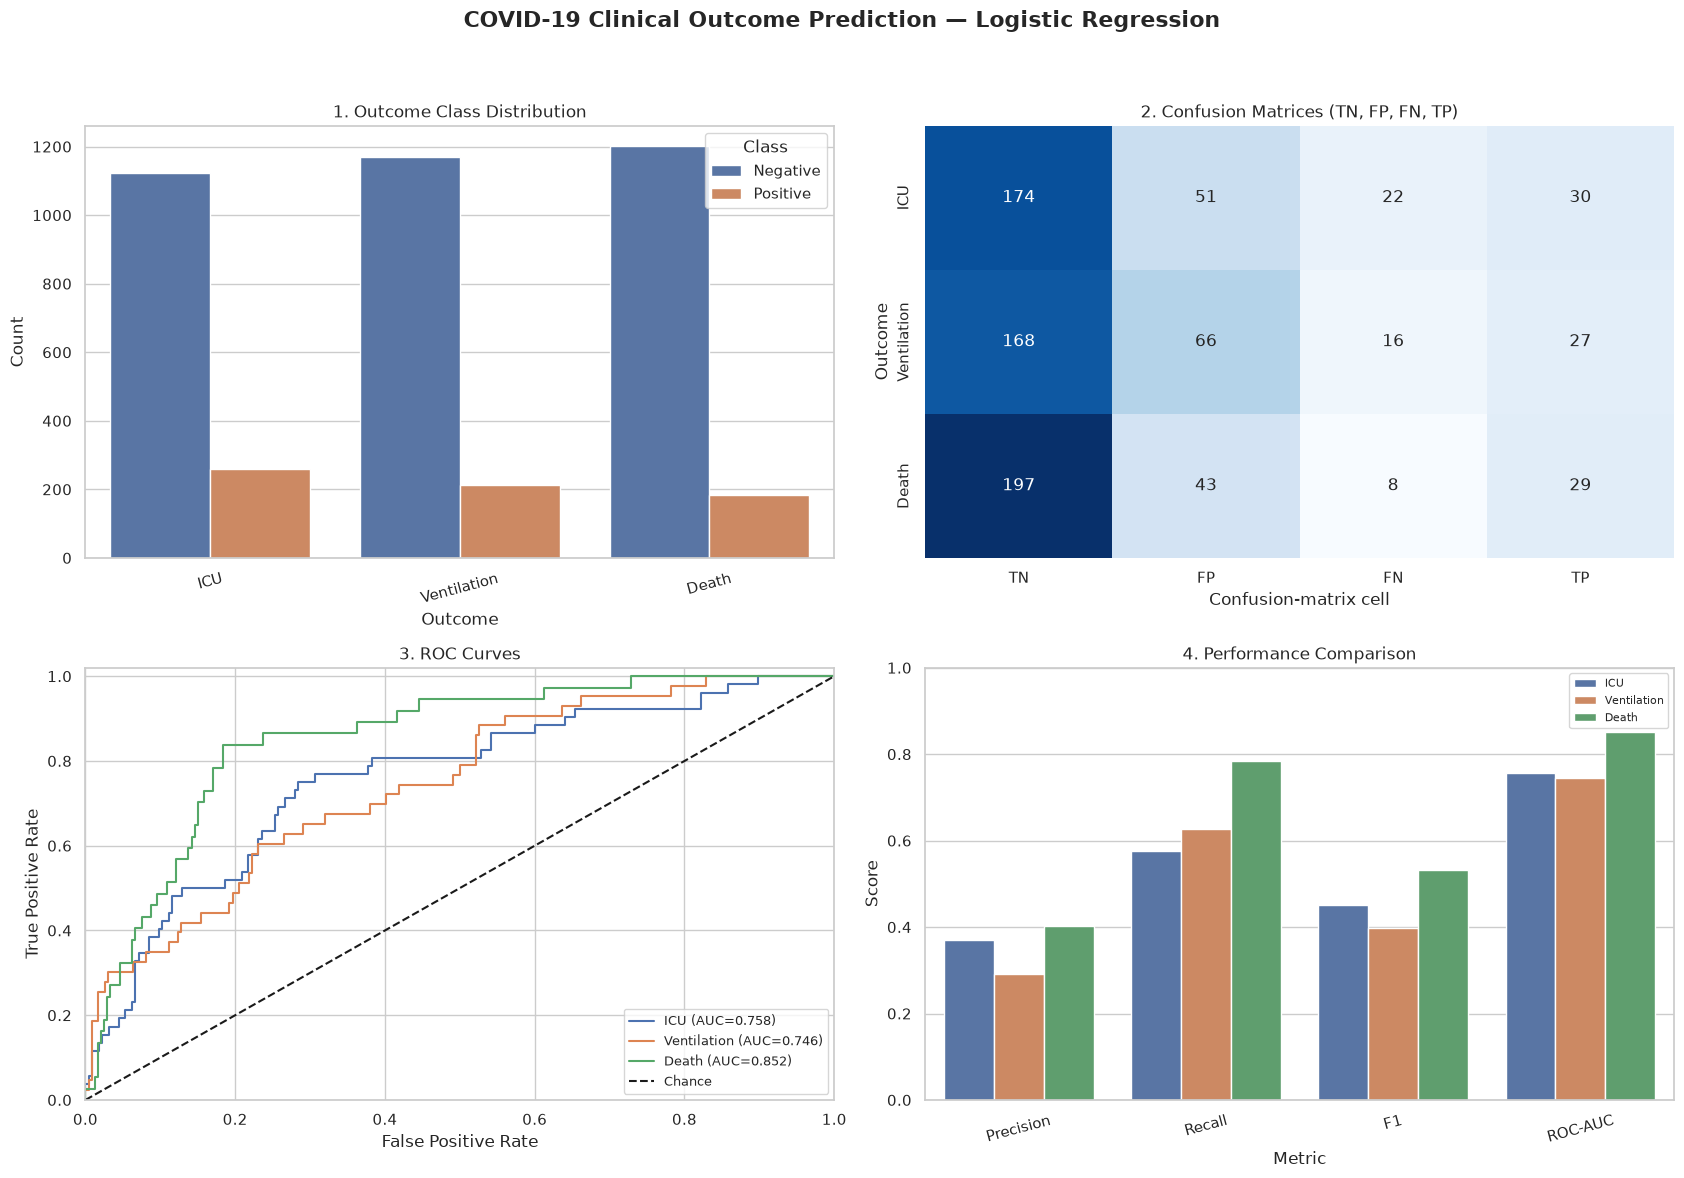

Saved figure: plots/covid19_all_four_plots.png
Saved metrics: plots/plot_metrics.csv


,Outcome,Accuracy,Precision,Recall,F1,ROC-AUC
0,ICU,0.736,0.370,0.577,0.451,0.758
1,Ventilation,0.704,0.290,0.628,0.397,0.746
2,Death,0.816,0.403,0.784,0.532,0.852


In [8]:
# FINAL CELL: Generate all 4 plots from the existing notebook's data

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix, roc_curve, roc_auc_score,
    accuracy_score, precision_score, recall_score, f1_score
)

os.makedirs("plots", exist_ok=True)
sns.set_theme(style="whitegrid")

targets_to_plot = ["ICU", "Ventilation", "Death"]
saved_predictions = {}
plot_metrics = []
class_rows = []

# Retrain each model so test predictions are available for plotting
for target in targets_to_plot:
    valid = patient_df[target].notna()
    X_target = patient_df.loc[valid, feature_cols].copy()
    y_target = patient_df.loc[valid, target].astype(int)

    counts = y_target.value_counts()
    for label in [0, 1]:
        class_rows.append({
            "Outcome": target,
            "Class": "Negative" if label == 0 else "Positive",
            "Count": int(counts.get(label, 0))
        })

    if y_target.nunique() != 2 or counts.min() < 2:
        print(f"Skipping {target}: insufficient examples.")
        continue

    X_train, X_test, y_train, y_test = train_test_split(
        X_target, y_target,
        test_size=0.20, random_state=42, stratify=y_target
    )

    # Infer feature types from training data
    numeric_cols = X_train.select_dtypes(
        include=["number", "bool"]
    ).columns.tolist()
    categorical_cols = [
        c for c in X_train.columns if c not in numeric_cols
    ]

    transformers = []
    if numeric_cols:
        transformers.append((
            "num",
            Pipeline([("imputer", SimpleImputer(strategy="median"))]),
            numeric_cols
        ))
    if categorical_cols:
        transformers.append((
            "cat",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(handle_unknown="ignore"))
            ]),
            categorical_cols
        ))

    model = Pipeline([
        ("preprocessor", ColumnTransformer(transformers)),
        ("classifier", LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            solver="liblinear",
            random_state=42
        ))
    ])

    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    saved_predictions[target] = {
        "y_true": y_test.to_numpy(),
        "y_pred": y_pred,
        "y_prob": y_prob
    }

    plot_metrics.append({
        "Outcome": target,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

metrics_df = pd.DataFrame(plot_metrics)
metrics_df.to_csv("plots/plot_metrics.csv", index=False)

# Create one 2x2 figure
fig, axes = plt.subplots(2, 2, figsize=(17, 12))
fig.suptitle(
    "COVID-19 Clinical Outcome Prediction — Logistic Regression",
    fontsize=16, fontweight="bold"
)

# Plot 1: Outcome class distributions
class_df = pd.DataFrame(class_rows)
sns.barplot(
    data=class_df, x="Outcome", y="Count",
    hue="Class", ax=axes[0, 0]
)
axes[0, 0].set_title("1. Outcome Class Distribution")
axes[0, 0].tick_params(axis="x", rotation=15)

# Plot 2: Confusion matrices, with one small matrix per outcome
axes[0, 1].axis("off")
available = list(saved_predictions.keys())
if available:
    # Embed three matrices as an image grid in this subplot
    ax = axes[0, 1]
    ax.axis("on")
    ax.set_title("2. Confusion Matrices (TN, FP, FN, TP)")
    combined = np.vstack([
        confusion_matrix(
            saved_predictions[t]["y_true"],
            saved_predictions[t]["y_pred"],
            labels=[0, 1]
        ).ravel()
        for t in available
    ])

    sns.heatmap(
        combined, annot=True, fmt="d", cmap="Blues",
        xticklabels=["TN", "FP", "FN", "TP"],
        yticklabels=available, ax=ax, cbar=False
    )
    ax.set_xlabel("Confusion-matrix cell")
    ax.set_ylabel("Outcome")

# Plot 3: ROC curves
ax = axes[1, 0]
for target, pred in saved_predictions.items():
    fpr, tpr, _ = roc_curve(pred["y_true"], pred["y_prob"])
    auc = roc_auc_score(pred["y_true"], pred["y_prob"])
    ax.plot(fpr, tpr, label=f"{target} (AUC={auc:.3f})")

ax.plot([0, 1], [0, 1], "k--", label="Chance")
ax.set_title("3. ROC Curves")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.legend(fontsize=9)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)

# Plot 4: Performance comparison across outcomes
ax = axes[1, 1]
if not metrics_df.empty:
    metrics_long = metrics_df.melt(
        id_vars="Outcome",
        value_vars=["Precision", "Recall", "F1", "ROC-AUC"],
        var_name="Metric",
        value_name="Score"
    )
    sns.barplot(
        data=metrics_long, x="Metric", y="Score",
        hue="Outcome", ax=ax
    )
    ax.set_ylim(0, 1)
    ax.set_title("4. Performance Comparison")
    ax.tick_params(axis="x", rotation=15)
    ax.legend(fontsize=8)
else:
    ax.text(0.5, 0.5, "No results available", ha="center")

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig("plots/covid19_all_four_plots.png",
            dpi=300, bbox_inches="tight")
plt.show()

print("Saved figure: plots/covid19_all_four_plots.png")
print("Saved metrics: plots/plot_metrics.csv")
display(metrics_df.round(3))